10 10 2


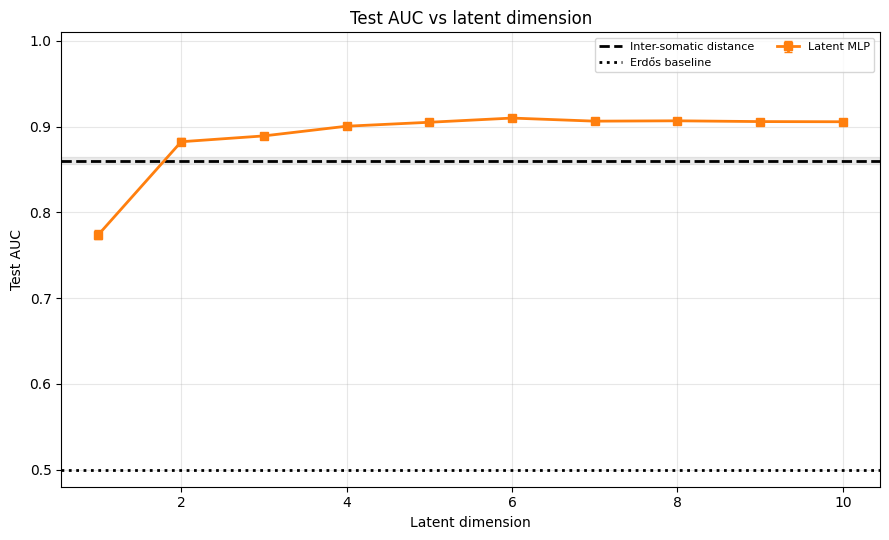

In [24]:
import numpy as np
import matplotlib.pyplot as plt

# =========================
# Data
# =========================

dims = np.arange(1, 11)

paper_auc = np.array([
    0.5050, 0.5039, 0.5558,
    0.6419, 0.7192, 0.7828,
    0.8277, 0.8644, 0.8722,
    0.8730, 0.8707, 0.8705,
    0.8705, 0.8680, 0.8663
])

paper_ci_low = np.array([
    0.4989, 0.4977, 0.5505,
    0.6351, 0.7117, 0.7760,
    0.8222, 0.8600, 0.8683,
    0.8698, 0.8672, 0.8670,
    0.8672, 0.8648, 0.8631
])

paper_ci_high = np.array([
    0.5115, 0.5099, 0.5618,
    0.6484, 0.7271, 0.7898,
    0.8336, 0.8688, 0.8760,
    0.8760, 0.8740, 0.8738,
    0.8736, 0.8711, 0.8699
])

latent_mlp_auc = np.array([
    0.7741, 0.8824, 0.8892,
    0.9005, 0.9051, 0.9100,
    0.9064, 0.9068, 0.9059,
    0.9057, 0.9097, 0.9076,
    0.9079, 0.9065, 0.9074
][:10])

latent_mlp_ci_low = np.array([
    0.7687, 0.8788, 0.8858,
    0.8970, 0.9024, 0.9073,
    0.9037, 0.9038, 0.9027,
    0.9028, 0.9064, 0.9050,
    0.9056, 0.9037, 0.9043
][:10])

latent_mlp_ci_high = np.array([
    0.7799, 0.8862, 0.8927,
    0.9035, 0.9082, 0.9124,
    0.9094, 0.9099, 0.9087,
    0.9085, 0.9128, 0.9106,
    0.9107, 0.9092, 0.9101
][:10])

hybrid_dims = np.array([4, 5, 6, 7, 8, 9])

hybrid_auc = np.array([
    0.9092, 0.9121, 0.9155,
    0.9159, 0.9195, 0.9182
])

hybrid_ci_low = np.array([
    0.9070, 0.9094, 0.9128,
    0.9131, 0.9166, 0.9157
])

hybrid_ci_high = np.array([
    0.9124, 0.9153, 0.9183,
    0.9181, 0.9219, 0.9203
])

# Baselines with 95% CI
geometry_auc = 0.8604
erdos_auc = 0.50

geometry_ci_low = 0.8559
geometry_ci_high = 0.8650

readout_auc = 0.8045
readout_ci_low = 0.7971
readout_ci_high = 0.8110

readout_rf_auc = 0.8406
readout_rf_ci_low = 0.8346
readout_rf_ci_high = 0.8468

readout_xyz_auc = 0.9025
readout_xyz_ci_low = 0.8987
readout_xyz_ci_high = 0.9061

readout_xyz_rf_auc = 0.9025
readout_xyz_rf_ci_low = 0.8987
readout_xyz_rf_ci_high = 0.9067

# small visual offset to avoid perfect overlap
readout_xyz_auc_plot = readout_xyz_auc - 0.0015
readout_xyz_ci_low_plot = readout_xyz_ci_low - 0.0015
readout_xyz_ci_high_plot = readout_xyz_ci_high - 0.0015


# =========================
# Plot
# =========================

plt.figure(figsize=(9, 5.5))

"""# Latent models
plt.errorbar(
    dims,
    paper_auc,
    yerr=[paper_auc - paper_ci_low, paper_ci_high - paper_auc],
    color="tab:blue",
    marker="o",
    linestyle="-",
    linewidth=2,
    capsize=3,
    label="Paper model"
)"""


print(len(dims), len(latent_mlp_auc), len([latent_mlp_auc - latent_mlp_ci_low, latent_mlp_ci_high - latent_mlp_auc]))
plt.errorbar(
    dims,
    latent_mlp_auc,
    yerr=[latent_mlp_auc - latent_mlp_ci_low, latent_mlp_ci_high - latent_mlp_auc],
    color="tab:orange",
    marker="s",
    linestyle="-",
    linewidth=2,
    capsize=3,
    label="Latent MLP"
)

"""plt.errorbar(
    hybrid_dims,
    hybrid_auc,
    yerr=[hybrid_auc - hybrid_ci_low, hybrid_ci_high - hybrid_auc],
    color="tab:red",
    marker="D",
    linestyle="-",
    linewidth=2.5,
    capsize=3,
    label="Hybrid: 3D geo + latent"
)"""

# Geometric / null baselines
plt.axhspan(
    geometry_ci_low,
    geometry_ci_high,
    color="black",
    alpha=0.08
)

plt.axhline(
    geometry_auc,
    color="black",
    linestyle="--",
    linewidth=2,
    label="Inter-somatic distance"
)

plt.axhline(
    erdos_auc,
    color="black",
    linestyle=":",
    linewidth=2,
    label="Erdős baseline"
)

# Functional baselines
# Functional baselines with CI bands
"""plt.axhspan(
    readout_ci_low,
    readout_ci_high,
    color="tab:green",
    alpha=0.08
)

plt.axhline(
    readout_auc,
    color="tab:green",
    linestyle=(0, (3, 1, 1, 1)),
    linewidth=2,
    label="Readout weights"
)

plt.axhspan(
    readout_rf_ci_low,
    readout_rf_ci_high,
    color="tab:green",
    alpha=0.08
)

plt.axhline(
    readout_rf_auc,
    color="tab:green",
    linestyle="--",
    linewidth=2,
    label="Readout + RF center"
)

plt.axhspan(
    readout_xyz_ci_low_plot,
    readout_xyz_ci_high_plot,
    color="tab:green",
    alpha=0.08
)

plt.axhline(
    readout_xyz_auc_plot,
    color="tab:green",
    linestyle="dotted",
    linewidth=2,
    alpha=0.85,
    label="Readout + 3D geo"
)

plt.axhspan(
    readout_xyz_rf_ci_low,
    readout_xyz_rf_ci_high,
    color="tab:green",
    alpha=0.10
)

plt.axhline(
    readout_xyz_rf_auc,
    color="tab:green",
    linestyle="-",
    linewidth=2.5,
    label="Readout + RF center + 3D geo"
)"""
plt.xlabel("Latent dimension")
plt.ylabel("Test AUC")
plt.title("Test AUC vs latent dimension")

plt.ylim(0.48, 1.01)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=8, ncol=2)

plt.tight_layout()
plt.show()